In [19]:
!pip install vaderSentiment

TEXT PREPROCESSING PIPELINE:
*Text Cleaning: Removing punctuation, digits, and special characters using the re library.
*Tokenization: Splitting sentences into individual words.
*Stopword Removal: Removing common English words using the NLTK stopword list.
*Lemmatization: We chose Lemmatization over stemming because it produces a valid base form that can be found in a dictionary, making it more accurate than stemming. The primary goal of this technique is to reduce the number of unique words in a text document, making it easier to analyze and understand.

In [2]:
import re
import nltk

def clean_text(text):
    text=re.sub(r'[^a-zA-Z\s]',' ',text)
    #will remove punctuation marks
    text=re.sub(r'\s+',' ', text)
    #will remove extra spaces
    text=text.lower().strip()
    #lowercase the text
    return text

def tokenize(text):
    return text.split()

from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
def remove_stopwords(tokens):
    return [word for word in tokens if word not in stop_words]

# Method used- Lemmatization
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')
lemmatizer = WordNetLemmatizer()
def lemmatize_tokens(tokens):
    return [lemmatizer.lemmatize(word) for word in tokens]

#Full preprocessing pipeline
def preprocess_text(text):
    cleaned = clean_text(text) #Text Cleaning
    tokens = tokenize(cleaned) #Tokenization
    tokens = remove_stopwords(tokens) #Stopword Removal
    tokens = lemmatize_tokens(tokens) #Lemmatization
    return tokens

#Example:
preprocess_text("The company's profits increased significantly in 2023!")

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/anshusingh/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/anshusingh/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


['company', 'profit', 'increased', 'significantly']

QUESTION 1: CELL 1-4
LM BASED SENTIMENT ANALYSIS AND OPTIMIZATION:
In this part we utilize the Loughran-McDonald sentiment lexicon, focusing specifically on the Positive and Negative categories.
*Rule Based System: A sentence is classified as Positive if the positive word count is higher, and Negative if the negative count is higher.
*Optimization: To improve speed, we store the lexicon in Python Sets. This allows for O(1) average time complexity for word lookups, making the system significantly faster than using lists.

In [16]:
import pandas as pd

lm_df = pd.read_csv("loughran-mcdonald.csv") #importing the provided lexicon

positive_words = set(lm_df[lm_df['Positive'] > 0]['Word'].str.lower())
negative_words = set(lm_df[lm_df['Negative'] > 0]['Word'].str.lower())
#creating python sets of positve and negative words

def lm_sentiment(tokens): #counting number of positive and negative words
    pos_count = sum(1 for word in tokens if word in positive_words)
    neg_count = sum(1 for word in tokens if word in negative_words)

    if pos_count > neg_count:
        return "Positive"
    elif neg_count > pos_count:
        return "Negative"
    else:
        return "Neutral"

#Applying on given dataset
df_q1 = pd.read_csv('Dataset_for_Q1.csv')#importing the dataset
df_q1['Tokens'] = df_q1['text'].apply(preprocess_text)#applying preprocessing
df_q1['LM_Predicted'] = df_q1['Tokens'].apply(lm_sentiment_analysis)#applying LM sentiment
print("LM Predictions complete.")
print(df_q1[['text', 'LM_Predicted']].head())



LM Predictions complete.
                                                text LM_Predicted
0  HDFC Bank invests in QNu Labs, a pioneer in qu...      NEUTRAL
1  HDFC Bank sees 2,408 put option contracts trad...     NEGATIVE
2  Eight top firms lost ₹2.24 trn in valuation, l...     NEGATIVE
3  SBI's Q1 profits grew 12.5% YoY to Rs 19,160.4...     POSITIVE
4  India Inc boosts overseas borrowing post S&P u...      NEUTRAL


VADER SENTIMENT ANALYSIS:
Vader is effective for analyzing sentiment intensity. We use the compound score and apply the standard thresholds to assign labels.
*Positive: score ≥ 0.05
*Negative: score ≤ -0.05
*Neutral: score between -0.05 and 0.05

In [20]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def get_vader_label(text):
    score = analyzer.polarity_scores(text)['compound']
    if score >= 0.05:
        return "POSITIVE"
    elif score <= -0.05:
        return "NEGATIVE"
    else:
        return "NEUTRAL"

df_q1['VADER_Predicted'] = df_q1['text'].apply(get_vader_label)#Applying Vader predictions
print("VADER Predictions complete.")
print(df_q1[['text', 'VADER_Predicted']].head())

VADER Predictions complete.
                                                text VADER_Predicted
0  HDFC Bank invests in QNu Labs, a pioneer in qu...         NEUTRAL
1  HDFC Bank sees 2,408 put option contracts trad...        POSITIVE
2  Eight top firms lost ₹2.24 trn in valuation, l...        NEGATIVE
3  SBI's Q1 profits grew 12.5% YoY to Rs 19,160.4...        POSITIVE
4  India Inc boosts overseas borrowing post S&P u...        POSITIVE


Evaluation Metrics:
we calculate the performance metrics for both the LM-based method and VADER. We report the following percentages:
*Correct Positive Percentage
*Correct Negative Percentage
*Overall Accuracy Percentage

--- Accuracy Metrics Comparison ---
                   Correct Positive %  Correct Negative %  Overall Accuracy %
Loughran-McDonald           46.529081           65.916955           58.459215
VADER                       82.270169           39.013841           51.548338


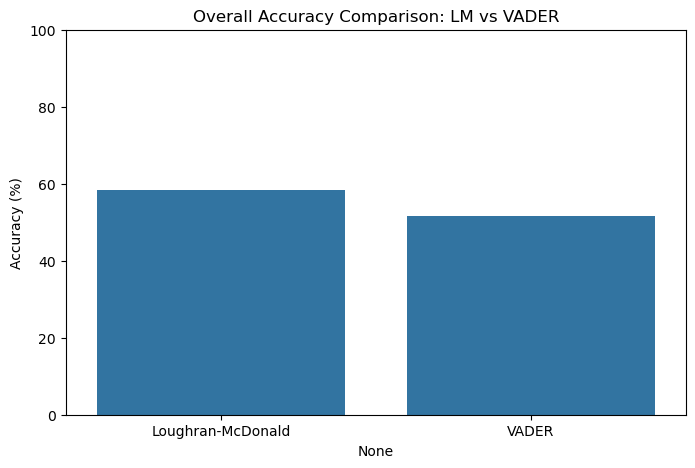

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

def calculate_metrics(df, pred_col, true_col='label'):
    # Capitalization of labels for proper comparison (POSITIVE, NEGATIVE, NEUTRAL)
    df[true_col] = df[true_col].str.upper()
    df[pred_col] = df[pred_col].str.upper()
    # Filter for Positive and Negative sentences
    pos_df = df[df[true_col] == 'POSITIVE']
    neg_df = df[df[true_col] == 'NEGATIVE']
    # Calculations as per formulas:
    correct_pos_perc = (len(pos_df[pos_df[pred_col] == 'POSITIVE']) / len(pos_df)) * 100 if len(pos_df) > 0 else 0
    correct_neg_perc = (len(neg_df[neg_df[pred_col] == 'NEGATIVE']) / len(neg_df)) * 100 if len(neg_df) > 0 else 0
    overall_acc = accuracy_score(df[true_col], df[pred_col]) * 100
    return [correct_pos_perc, correct_neg_perc, overall_acc]

# Metrics results
lm_metrics = calculate_metrics(df_q1, 'LM_Predicted')
vader_metrics = calculate_metrics(df_q1, 'VADER_Predicted')

#Table format
metrics_summary = pd.DataFrame([lm_metrics, vader_metrics], 
                               columns=['Correct Positive %', 'Correct Negative %', 'Overall Accuracy %'],
                               index=['Loughran-McDonald', 'VADER'])
print("--- Accuracy Metrics Comparison ---")
print(metrics_summary)

# Visualizations (Bar chart for Overall Accuracy)
plt.figure(figsize=(8, 5))
sns.barplot(x=metrics_summary.index, y=metrics_summary['Overall Accuracy %'])
plt.title('Overall Accuracy Comparison: LM vs VADER')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.show()

QUESTION 2:
we implement and compare Machine Learning models for sentiment classification. The dataset contains three sentiment classes:
+1: Positive 
0: Neutral 
-1: Negative 

Part A: Feature Engineering and Data Split
We prepare the text data by applying the preprocessing pipeline defined in Question 1.
*Train-Test Split: We use a 70-30 split (70% training, 30% testing) as required.
*TF-IDF Vectorization: This converts text into numerical features based on word importance. We use ngram_range=(1, 2) to capture both single words and two-word phrases.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extrac tion.text import TfidfVectorizer
import pandas as pd

df_q2 = pd.read_excel('Dataset_for_Q2.xlsx')#importing the given dataset
print("Columns in Q2 dataset:", df_q2.columns.tolist())

text_col = 'Headlines' if 'Headlines' in df_q2.columns else 'text'
label_col = 'sentiment_label' if 'sentiment_label' in df_q2.columns else 'label'

# 2. Apply preprocessing
df_q2['Cleaned_Text'] = df_q2[text_col].apply(lambda x: " ".join(preprocess_text(str(x))))

# 3. Perform 70-30 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    df_q2['Cleaned_Text'], 
    df_q2[label_col], 
    test_size=0.30, 
    random_state=42,
    stratify=df_q2[label_col]
)
# 4. TF-IDF Vectorization
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"Data split and TF-IDF vectorization complete. Training samples: {X_train_tfidf.shape[0]}")

Columns in Q2 dataset: ['Sno', 'Headlines', 'sentiment_label']
Data split and TF-IDF vectorization complete. Training samples: 13031


Part B: Naive Bayes Classifier
We implement a Multinomial Naive Bayes classifier, which is a standard baseline for text classification tasks. We report the overall accuracy and class-wise metrics (Precision, Recall, and F1-Score).

In [27]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score

# Initialize and train the Naive Bayes model
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test_tfidf)

# Evaluation
print("Naive Bayes Classification Report: ")
print(classification_report(y_test, y_pred_nb))
print(f"Naive Bayes Overall Accuracy: {accuracy_score(y_test, y_pred_nb)*100:.2f}%")

Naive Bayes Classification Report: 
              precision    recall  f1-score   support

    Negative       0.49      0.47      0.48      1839
     Neutral       0.86      0.80      0.83      1837
    Positive       0.52      0.57      0.54      1910

    accuracy                           0.61      5586
   macro avg       0.62      0.62      0.62      5586
weighted avg       0.62      0.61      0.62      5586

Naive Bayes Overall Accuracy: 61.49%


Part C: Logistic Regression Classifier 
We implement a Logistic Regression classifier to compare its performance against the Naive Bayes model. Logistic Regression is often more robust as it models the relationship between features and labels using a logistic function.

In [28]:
from sklearn.linear_model import LogisticRegression

# Initialize and train the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test_tfidf)

# Evaluation
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr))
print(f"Logistic Regression Overall Accuracy: {accuracy_score(y_test, y_pred_lr)*100:.2f}%")

Logistic Regression Classification Report:
              precision    recall  f1-score   support

    Negative       0.49      0.46      0.47      1839
     Neutral       0.86      0.86      0.86      1837
    Positive       0.52      0.56      0.54      1910

    accuracy                           0.62      5586
   macro avg       0.62      0.62      0.62      5586
weighted avg       0.62      0.62      0.62      5586

Logistic Regression Overall Accuracy: 62.28%


Model Comparison and Visualization:
visualizing the performance of both Machine Learning models to determine which is more effective for financial sentiment analysis.

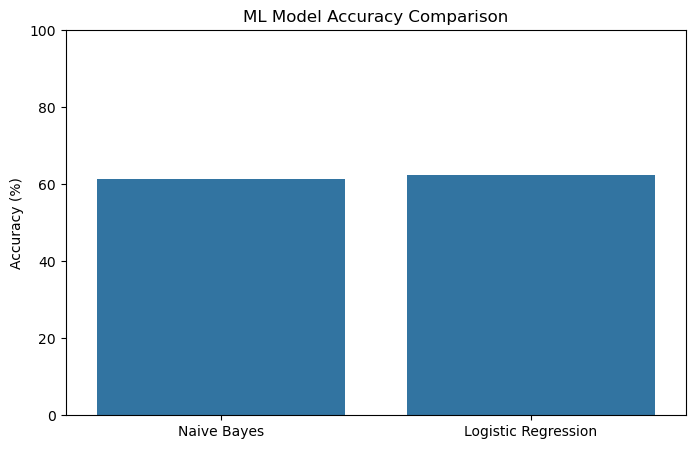

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Comparing accuracies
models = ['Naive Bayes', 'Logistic Regression']
accuracies = [accuracy_score(y_test, y_pred_nb)*100, accuracy_score(y_test, y_pred_lr)*100]

plt.figure(figsize=(8, 5))
sns.barplot(x=models, y=accuracies,)
plt.title('ML Model Accuracy Comparison')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.show()